# PPSA WY 2025 | All snow pit profiles

Compare all ten field days against the HRRR-AK and Met Mixed soil simulations.
The columns start at ground level and show the observed and native simulated
profiles. The ranking at the end identifies the closest cold and warm matches. Use the
[publication selector](select_table2_snowpit.ipynb) to choose the dates shown in the manuscript.

In [1]:
import mmap
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.patches import Rectangle
from IPython.display import display
import numpy as np
import pandas as pd

root = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'figures/data/ppsa_snowpit_profiles_WY2025.csv').is_file())
output_dir = root / 'figures/files'
model_dir = Path('/home/cassie/python/models/run_snowpack/sites/ppsa/output')
field_file = root / 'figures/data/ppsa_snowpit_profiles_WY2025.csv'

model_files = {
    'HRRR-AK': model_dir / 'hrrrak_lapserate_ppsa_WY2020-WY2025_soil.pro',
    'Met mixed': model_dir / 'met_hrrrak_lapserate_ppsa_WY2020-WY2025_soil.pro',
}

## Observation and simulation profiles

The [field CSV](../data/ppsa_snowpit_profiles_WY2025.csv) preserves density
intervals and individual temperature readings. Air and ground temperatures are
outside the snow profile. Repeated readings at one height are averaged for the
comparison. Each run is sampled at 12:00 in its profile time coordinate on the
field date, the convention used in Table 2. Field visits occurred at different
times of day.

In [2]:
def read_profile(path, timestamp):
    prefix = timestamp.strftime('0500,%d.%m.%Y %H:%M:%S').encode()
    fields = {}
    with path.open('rb') as stream, mmap.mmap(stream.fileno(), 0, access=mmap.ACCESS_READ) as data:
        start = data.find(prefix)
        if start < 0:
            raise ValueError(f'No exact profile at {timestamp} in {path.name}')
        data.seek(start)
        data.readline()
        for line in iter(data.readline, b''):
            if line.startswith(b'0500,'):
                break
            if line.startswith((b'0501,', b'0502,', b'0503,')):
                key, count, payload = line.split(b',', 2)
                values = np.fromstring(payload.decode(), sep=',')
                if len(values) != int(count):
                    raise ValueError(f'Invalid {key!r} element count in {path.name}')
                fields[key] = values
    heights, density, temperature = (fields[k] for k in (b'0501', b'0502', b'0503'))
    if len(heights) != len(density) + 1 or len(density) != len(temperature):
        raise ValueError(f'Unexpected soil profile geometry in {path.name}')
    snow = heights[1:] > 0
    lower = np.maximum(heights[:-1][snow], 0)
    upper = heights[1:][snow]
    if not len(upper) or np.any(upper <= lower):
        raise ValueError(f'No ordered snow layers at {timestamp} in {path.name}')
    return pd.DataFrame({
        'top_cm': upper[-1] - upper,
        'bottom_cm': upper[-1] - lower,
        'density_kg_m3': density[snow],
        'temperature_c': temperature[snow],
    }).iloc[::-1].reset_index(drop=True)

field = pd.read_csv(field_file, parse_dates=['date']).set_index('date')
dates = sorted(field.index.unique())
profiles = {
    day: {name: read_profile(path, day + pd.Timedelta(hours=12))
          for name, path in model_files.items()}
    for day in dates
}
bounds = ['top_cm', 'bottom_cm']


def temperature_points(rows):
    snow = rows.loc[rows['temperature_location'].isin(['snow', 'surface'])]
    return snow.groupby('temperature_height_cm', sort=True)['temperature_c'].mean()


def ground_bands(bands, depth):
    return bands.assign(top_cm=depth - bands['bottom_cm'],
                        bottom_cm=depth - bands['top_cm'])

## Density and temperature columns

Nearby colors indicate similar values. Overlapping density intervals appear side
by side. Temperature is interpolated between the measured heights for display,
and the dots mark those heights. Blank regions indicate that no observation
was available at that height. Model columns retain the native layer geometry.

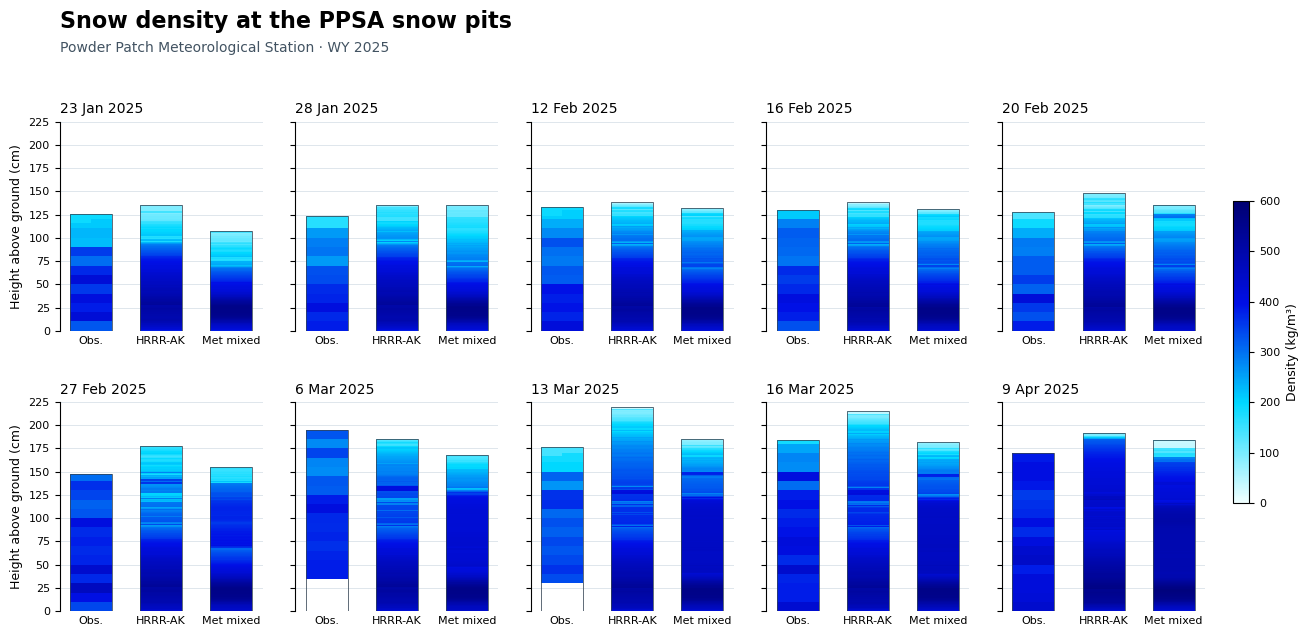

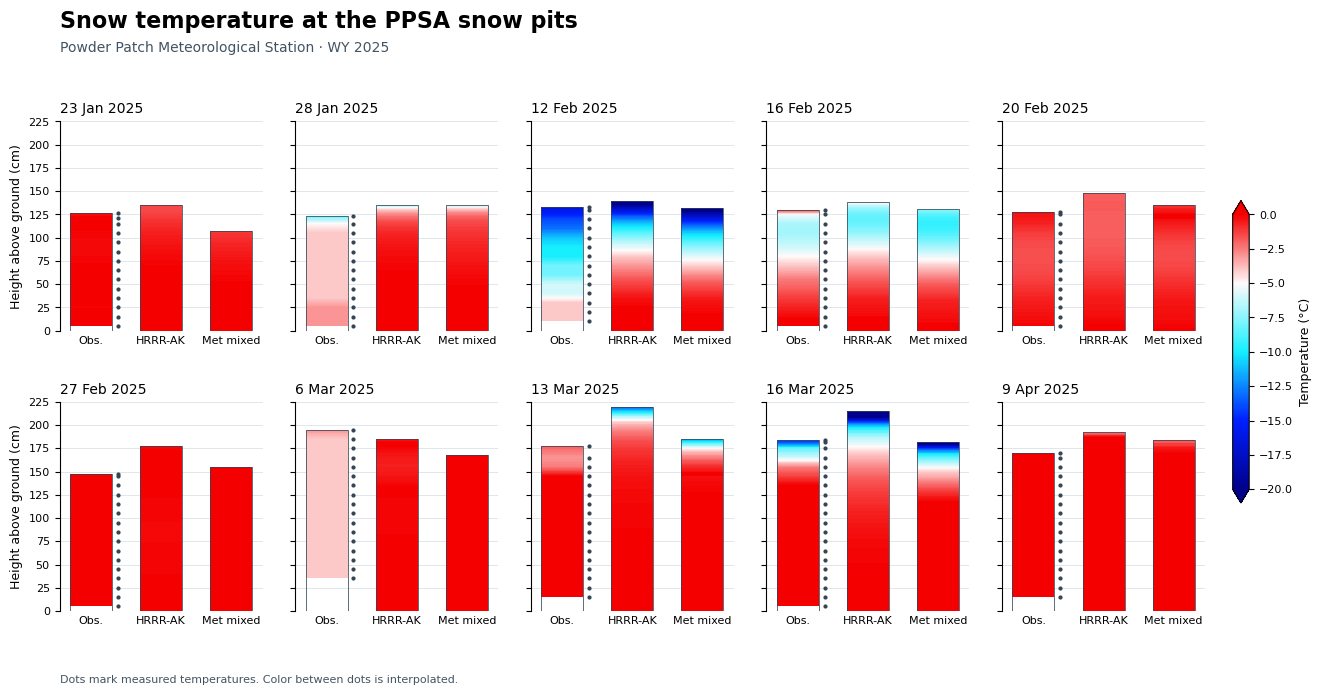

In [3]:
density_cmap = LinearSegmentedColormap.from_list(
    'density', [(0, '#f1ffff'), (0.33, '#00d8ff'), (0.66, '#000fe6'), (1, '#000071')]
)
temperature_cmap = LinearSegmentedColormap.from_list(
    'temperature', [(0, '#00008b'), (0.25, '#001fff'), (0.50, '#15efff'),
                    (0.75, '#fffafa'), (1, '#f40000')]
)
variables = {
    'density_kg_m3': ('Snow density', 'Density (kg/m³)', density_cmap, Normalize(0, 600)),
    'temperature_c': ('Snow temperature', 'Temperature (°C)', temperature_cmap, Normalize(-20, 0)),
}

def draw_bands(ax, left, right, layers, variable, cmap, norm):
    vertices = [[(lo, top), (hi, top), (hi, bottom), (lo, bottom)]
                for lo, hi, (top, bottom) in zip(
                    np.broadcast_to(left, len(layers)), np.broadcast_to(right, len(layers)),
                    layers[bounds].itertuples(index=False, name=None))]
    ax.add_collection(PolyCollection(vertices, array=layers[variable].to_numpy(),
                                     cmap=cmap, norm=norm, edgecolors='none',
                                     antialiaseds=False, zorder=2))


def observed_density(rows, depth):
    density = rows.loc[rows['measurement'].eq('density')]
    top = depth - density['top_height_cm'].to_numpy()
    bottom = depth - density['bottom_height_cm'].to_numpy()
    edges = np.unique(np.r_[top, bottom])
    bands = []
    for shallow, deep in zip(edges[:-1], edges[1:]):
        values = density.loc[(top <= shallow) & (bottom >= deep), 'density_kg_m3']
        slots = np.linspace(-0.30, 0.30, len(values) + 1)
        bands.extend((lo, hi, shallow, deep, value)
                     for lo, hi, value in zip(slots[:-1], slots[1:], values))
    return pd.DataFrame(bands, columns=['left', 'right', *bounds, 'density_kg_m3'])

depths = [frame['bottom_cm'].max() for day in profiles.values() for frame in day.values()]
depth_limit = 25 * np.ceil((max(*depths, field['snow_depth_cm'].max()) + 5) / 25)
output_dir.mkdir(parents=True, exist_ok=True)

for variable, (title, unit, cmap, norm) in variables.items():
    with mpl.rc_context({'font.family': 'DejaVu Sans', 'pdf.fonttype': 42}):
        fig, axes = plt.subplots(2, 5, figsize=(13.8, 7.2), sharey=True,
                                 gridspec_kw=dict(left=0.07, right=0.90, top=0.82, bottom=0.14,
                                                  hspace=0.34, wspace=0.16))
        for i, (ax, day) in enumerate(zip(axes.flat, dates)):
            rows = field.loc[day]
            depth = rows['snow_depth_cm'].iloc[0]
            if variable == 'density_kg_m3':
                bands = ground_bands(observed_density(rows, depth), depth)
                draw_bands(ax, bands['left'], bands['right'], bands, variable, cmap, norm)
            else:
                points = temperature_points(rows)
                edges = np.linspace(points.index.min(), points.index.max(), 201)
                bands = pd.DataFrame({
                    'top_cm': edges[:-1], 'bottom_cm': edges[1:],
                    'temperature_c': np.interp((edges[:-1] + edges[1:]) / 2,
                                               points.index, points.to_numpy()),
                })
                draw_bands(ax, -0.30, 0.30, bands, variable, cmap, norm)
                ax.scatter(np.full(len(points), 0.38), points.index, s=4,
                           color='#344453', zorder=4)
            tops = [depth]
            for x, layers in enumerate(profiles[day].values(), 1):
                model_depth = layers['bottom_cm'].max()
                draw_bands(ax, x - 0.30, x + 0.30, ground_bands(layers, model_depth),
                           variable, cmap, norm)
                tops.append(model_depth)
            for x, top in enumerate(tops):
                ax.add_patch(Rectangle((x - 0.30, 0), 0.60, top, fill=False,
                                       edgecolor='#344453', linewidth=0.55, zorder=3))
            ax.set(xlim=(-0.45, 2.45), ylim=(0, depth_limit), xticks=[0, 1, 2],
                   xticklabels=['Obs.', 'HRRR-AK', 'Met mixed'])
            ax.set_title(f'{day:%-d %b %Y}', loc='left', fontsize=10)
            ax.tick_params(axis='both', labelsize=8)
            ax.tick_params(axis='x', length=0)
            ax.grid(axis='y', color='#dce4eb', linewidth=0.65)
            ax.set_axisbelow(True)
            ax.spines[['top', 'right', 'bottom']].set_visible(False)
            if i % 5 == 0:
                ax.set_ylabel('Height above ground (cm)', fontsize=9)

        cax = fig.add_axes([0.92, 0.29, 0.012, 0.42])
        data = np.concatenate([
            np.concatenate([frame[variable].to_numpy() for runs in profiles.values()
                            for frame in runs.values()]),
            field[variable].dropna().to_numpy() if variable == 'density_kg_m3'
            else field.loc[field['temperature_location'].isin(['snow', 'surface']), variable].to_numpy(),
        ])
        under, over = np.nanmin(data) < norm.vmin, np.nanmax(data) > norm.vmax
        extend = {(True, True): 'both', (True, False): 'min',
                  (False, True): 'max', (False, False): 'neither'}[under, over]
        bar = fig.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=cmap), cax=cax, extend=extend)
        bar.set_label(unit, fontsize=9)
        bar.ax.tick_params(labelsize=8)
        fig.text(0.07, 0.975, f'{title} at the PPSA snow pits', ha='left', va='top',
                 fontsize=16, weight='bold')
        fig.text(0.07, 0.932, 'Powder Patch Meteorological Station · WY 2025',
                 ha='left', va='top', fontsize=10, color='#425362')
        if variable == 'temperature_c':
            fig.text(0.07, 0.04, 'Dots mark measured temperatures. Color between dots is interpolated.',
                     fontsize=8, color='#425362')
        stem = 'figureX_all_snowpits_density' if variable == 'density_kg_m3' else 'figureX_all_snowpits_temperature'
        for extension in ('pdf', 'png'):
            fig.savefig(output_dir / f'{stem}.{extension}', dpi=300, facecolor='white')
        plt.show()

## Rank the best-matching cold and warm pits

Compare the two runs over the **same ground-relative heights**. Density RMSE
uses each fully matched measured interval, weighted by its thickness. Model
density is averaged over that interval using the overlap of native layers.
Overlapping field samples remain separate measurements for the RMSE. The
coverage check uses their union so overlapping intervals count once.

Temperature RMSE uses each distinct measured height within both modeled
columns. A pit must cover at least 75% of observed snow depth in both matched
density intervals and the matched temperature span. A pit is **warm** when
its observed mean temperature over the sampled span is at least −1 °C, and
**cold** otherwise. The mean is integrated linearly between recorded points.

The score averages the two runs' density RMSE divided by 50 kg/m³ and
temperature RMSE divided by 2 °C, with equal weight for the four terms.
Lower scores mean closer agreement. The flagged dates are suggestions from this campaign. All ten scores and the eligibility flags are shown here.

In [ ]:
def score_pit(day, rows, runs):
    depth = rows['snow_depth_cm'].iloc[0]
    points = temperature_points(rows)
    mean_temp = np.trapezoid(points.to_numpy(), points.index) / (points.index.max() - points.index.min())
    result = {'date': day, 'pit_class': 'warm' if mean_temp >= -1 else 'cold',
              'observed_mean_temperature_c': mean_temp}
    max_height = min(depth, *(frame['bottom_cm'].max() for frame in runs.values()))
    density = rows.loc[rows['measurement'].eq('density') & rows['top_height_cm'].le(max_height)]
    lo = density['bottom_height_cm'].to_numpy()
    hi = density['top_height_cm'].to_numpy()
    edges = np.unique(np.r_[lo, hi])
    enclosed = ((lo[:, None] <= edges[:-1]) & (hi[:, None] >= edges[1:])).any(axis=0)
    density_coverage = np.diff(edges)[enclosed].sum() / depth
    matched_temp = points.loc[points.index <= max_height]
    temperature_coverage = (matched_temp.index.max() - matched_temp.index.min()) / depth
    result.update(density_coverage=density_coverage, temperature_coverage=temperature_coverage)

    errors = []
    for name, profile in runs.items():
        model_depth = profile['bottom_cm'].max()
        bands = ground_bands(profile, model_depth).sort_values('top_cm')
        floor = bands['top_cm'].to_numpy()
        ceiling = bands['bottom_cm'].to_numpy()
        overlap = np.maximum(0, np.minimum(hi[:, None], ceiling) - np.maximum(lo[:, None], floor))
        np.testing.assert_allclose(overlap.sum(axis=1), hi - lo, atol=1e-6)
        modeled_density = overlap @ bands['density_kg_m3'].to_numpy() / (hi - lo)
        density_rmse = np.sqrt(np.average((modeled_density - density['density_kg_m3']) ** 2,
                                         weights=hi - lo))
        indices = np.searchsorted(ceiling, matched_temp.index, side='left')
        modeled_temperature = bands['temperature_c'].to_numpy()[indices]
        temp_rmse = np.sqrt(np.mean((modeled_temperature - matched_temp.to_numpy()) ** 2))
        prefix = 'hrrrak' if name == 'HRRR-AK' else 'met_mixed'
        result[f'{prefix}_density_rmse_kg_m3'] = density_rmse
        result[f'{prefix}_temperature_rmse_c'] = temp_rmse
        errors.extend([density_rmse / 50, temp_rmse / 2])

    return dict(result, eligible=min(density_coverage, temperature_coverage) >= 0.75,
                score=np.mean(errors))


ranked = pd.DataFrame([score_pit(day, field.loc[day], profiles[day]) for day in dates])
ranked = ranked.sort_values(['pit_class', 'score', 'date']).reset_index(drop=True)
selected = ranked.loc[ranked['eligible']].drop_duplicates('pit_class').copy()
if set(selected['pit_class']) != {'cold', 'warm'}:
    raise ValueError('The coverage rule did not yield both a cold and a warm pit.')
ranked['suggested'] = ranked['date'].isin(selected['date'])
display(ranked.assign(date=ranked['date'].dt.date).style.hide(axis='index').format(precision=2))

display(selected[['pit_class', 'date', 'score']].assign(date=selected['date'].dt.date))